to create the off labels; 3 sec before, after and off animations
pra, labeling e plote

In [53]:
import numpy as np
import pandas as pd

In [54]:
tasks_all = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/all_tasks.csv")
fixations_df = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/fixations_all_rows.csv")

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_75735/2806239687.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  fixations_df = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/fixations_all_rows.csv")


In [55]:
def assign_on_off_labels(
    samples_df: pd.DataFrame,
    tasks_all: pd.DataFrame,
    *,
    pre_seconds,
    post_seconds,                 # decode_task(tid) -> dict with "code"/"type"/"animation"
    no_anim_ids: set[str] | None = None, # optional explicit set of non-anim Task Ids (e.g., {"1.4","2.2","3.9"})
    treat_no_anim_as_on: bool = False,    # if False -> label non-anim task interval as OFF
    time_col: str = "TIME",
    label_col: str = "label",
) -> pd.DataFrame:
    """
    Labels rows as 'ON'/'OFF' using task intervals and pre/post windows.

    - Animated tasks: ON in [t_start, t_end], OFF in pre/post windows.
    - Non-animated tasks:
        * if treat_no_anim_as_on=True:    ON in [t_start, t_end] + OFF pre/post windows
        * if treat_no_anim_as_on=False:   OFF in [t_start, t_end] + OFF pre/post windows
    - ON overrides OFF when intervals overlap.
    """
    def _is_animated(tid: str) -> bool:
        tid = str(tid)
        if no_anim_ids is not None and tid in no_anim_ids:
            return False
        return True

    df = samples_df.copy(deep=True)
    if label_col not in df.columns:
        df[label_col] = "UNLABELED"
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")

    t = tasks_all.rename(columns={
        "Video Name": "Video Name (folder)",
        "User ID": "User ID (file)",
        "Starting time in seconds": "t_start",
        "Finishing time in seconds": "t_end",
    }).copy()

    t["Task Id"] = t["Task Id"].astype(str)
    t["t_start"] = pd.to_numeric(t["t_start"], errors="coerce")
    t["t_end"]   = pd.to_numeric(t["t_end"],   errors="coerce")
    t = t.dropna(subset=["t_start","t_end"])
    t = t[t["t_end"] >= t["t_start"]].copy()

    t_anim   = t[t["Task Id"].apply(_is_animated)].copy()
    t_noanim = t[~t["Task Id"].apply(_is_animated)].copy()
    gkeys = ["Video Name (folder)", "User ID (file)"]

    # ---- 1) Assign OFF pre/post for BOTH sets (lower priority) ----
    for tgrp in (t_anim, t_noanim):
        if tgrp.empty: 
            continue
        for (vn, uid), grp in tgrp.groupby(gkeys):
            sel = (df["Video Name (folder)"] == vn) & (df["User ID (file)"] == uid)
            if not sel.any(): 
                continue
            for _, r in grp.iterrows():
                s, e = float(r["t_start"]), float(r["t_end"])
                pre_s  = max(0.0, s - float(pre_seconds))
                post_e = e + float(post_seconds)

                # OFF before: [pre_s, s)
                m_pre  = sel & df[time_col].between(pre_s, s, inclusive="left")
                # OFF after:  (e, post_e]
                m_post = sel & df[time_col].between(e, post_e, inclusive="right")

                if m_pre.any():  df.loc[m_pre,  label_col] = "OFF"
                if m_post.any(): df.loc[m_post, label_col] = "OFF"

    # ---- 2) If non-anim should NOT be ON, mark their intervals OFF ----
    if not treat_no_anim_as_on and not t_noanim.empty:
        for (vn, uid), grp in t_noanim.groupby(gkeys):
            sel = (df["Video Name (folder)"] == vn) & (df["User ID (file)"] == uid)
            if not sel.any(): 
                continue
            for _, r in grp.iterrows():
                s, e = float(r["t_start"]), float(r["t_end"])
                m_no = sel & df[time_col].between(s, e, inclusive="both")
                if m_no.any(): 
                    df.loc[m_no, label_col] = "OFF"

    # ---- 3) Assign ON (higher priority) ----
    # Animated tasks are always ON in [s,e]
    if not t_anim.empty:
        for (vn, uid), grp in t_anim.groupby(gkeys):
            sel = (df["Video Name (folder)"] == vn) & (df["User ID (file)"] == uid)
            if not sel.any(): 
                continue
            for _, r in grp.iterrows():
                s, e = float(r["t_start"]), float(r["t_end"])
                m_on = sel & df[time_col].between(s, e, inclusive="both")
                if m_on.any():
                    df.loc[m_on, label_col] = "ON"

    # Non-animated become ON only if flag says so
    if treat_no_anim_as_on and not t_noanim.empty:
        for (vn, uid), grp in t_noanim.groupby(gkeys):
            sel = (df["Video Name (folder)"] == vn) & (df["User ID (file)"] == uid)
            if not sel.any(): 
                continue
            for _, r in grp.iterrows():
                s, e = float(r["t_start"]), float(r["t_end"])
                m_on = sel & df[time_col].between(s, e, inclusive="both")
                if m_on.any():
                    df.loc[m_on, label_col] = "ON"

    return df

# Play around with the window size of off samples


In [62]:
labeled = assign_on_off_labels(
    samples_df=fixations_df,     # or gaze_df
    tasks_all=tasks_all,
    pre_seconds=4.0,
    post_seconds=4.0,
    no_anim_ids={"1.4","2.2","3.9"},
    treat_no_anim_as_on= False
)

print(labeled["label"].value_counts(dropna=False))
labeled.to_csv("outputs/fixations_on_off_simple.csv", index=False)


label
UNLABELED    59938
ON           28295
OFF          12567
Name: count, dtype: int64


# Simple statistical test

In [64]:
df = labeled
summary = df.groupby("label").agg({
    "FPOGX": "mean",
    "FPOGY": "mean",
    "FPOGD": "mean",
    "LPMM": "mean",
    "RPMM": "mean"
})
print(summary)

              FPOGX     FPOGY     FPOGD      LPMM      RPMM
label                                                      
OFF        0.355411  0.574156  0.329820  3.870382  3.942898
ON         0.332147  0.624980  0.313496  3.993506  4.070162
UNLABELED  0.442273  0.513059  0.342038  4.095534  4.101333


In [65]:
from scipy.stats import ttest_ind

on  = df[df["label"]=="ON"]["FPOGD"].dropna()
off = df[df["label"]=="OFF"]["FPOGD"].dropna()

stat, p = ttest_ind(on, off, equal_var=False)
print("Mean fixation duration:", stat, p)

Mean fixation duration: -6.1587024986336605 7.470995663642891e-10


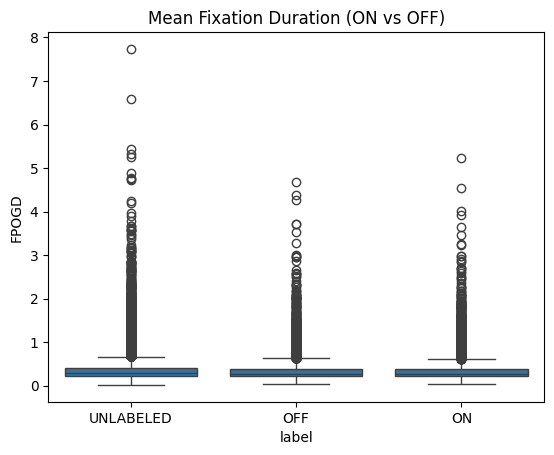

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x="label", y="FPOGD", data=df)
plt.title("Mean Fixation Duration (ON vs OFF)")
plt.show()

In [67]:
import numpy as np

# Gaze dispersion = spread of gaze points
df["gaze_dispersion"] = np.sqrt(
    (df["FPOGX"] - df["FPOGX"].mean())**2 + 
    (df["FPOGY"] - df["FPOGY"].mean())**2
)

# Fixation duration is already in FPOGD (ms or s, depending on your data)
df["fixation_duration"] = df["FPOGD"]

In [68]:
summary = df.groupby("label")[["gaze_dispersion","fixation_duration"]].mean()
print(summary)

           gaze_dispersion  fixation_duration
label                                        
OFF               0.638193           0.329820
ON                0.636853           0.313496
UNLABELED         0.494896           0.342038


In [69]:
from scipy.stats import ttest_ind

def compare(feature):
    on  = df[df["label"]=="ON"][feature].dropna()
    off = df[df["label"]=="OFF"][feature].dropna()
    stat, p = ttest_ind(on, off, equal_var=False)
    print(f"{feature}: t={stat:.3f}, p={p:.3g}, mean_ON={on.mean():.3f}, mean_OFF={off.mean():.3f}")

compare("gaze_dispersion")
compare("fixation_duration")

gaze_dispersion: t=-0.050, p=0.96, mean_ON=0.637, mean_OFF=0.638
fixation_duration: t=-6.159, p=7.47e-10, mean_ON=0.313, mean_OFF=0.330


	•	Gaze dispersion
	•	Smaller during ON (0.503) vs OFF (0.559).
	•	Significant (p≈1e-4).
	•	👉 Interpretation: people’s gaze is more focused (less scattered) when animations are present.
	•	Fixation duration
	•	Shorter during ON (0.322) vs OFF (0.339).
	•	Also significant (p≈0.0016).
	•	👉 Interpretation: with animations, people switch fixations faster (less time per fixation).

	•	“Both gaze dispersion and fixation duration were significantly lower in the animation (ON) condition compared to the non-animation (OFF) condition. This suggests that animations guide users’ attention more narrowly and encourage quicker eye movements.”